Чтобы улучшить результаты генерации текстур и переноса стиля, нужно сделать нормализацию весов сети VGG. Это нужно, поскольку обеспечит примерно равный вклад лосса, посчитанного по матрицам Грама. Таким образом, оптимизируемая функция должна быть более правильной с точки зрения наличия минимума. Следовательно, сам процесс оптимизации может давать лучшие результаты и проходить быстрее.

Основная идея: сделать нормализацию весов таким образом, чтобы для каждого фильтра каждого сверточного слоя средняя активация была равна единице, при этом выход самой сети должен остаться прежним. Разберемся, почему так можно сделать и как вообще считать среднюю активацию.

Наша сеть представляет из себя композицию сверток, ReLU и пулингов. Введем обозначения.

$N_l$ - количество фильтров в $l$-м сверточном слое;

$w_l, h_l$ - ширина и длина выхода фильтра в $l$-м сверточном слое;

$F^l$ - выход $l$-го сверточного слоя, имеет размер $N_l \times w_l \times h_l$. Тогда $F^l_i$ есть выход $l$-го сверточного слоя под действием $i$-го фильтра;

Каждый сверточный слой характеризуется матрицей весов, где по строкам расположены веса для соответствующего фильтра, а также вектором сдвига, где $i$-й элемент прибавляется ко всем элементам выхода свертки с $i$-м фильтром. Тогда обозначим:

$k_l$ - размер ядра свертки $l$-го сверточного слоя.

$W^l$ - многомерный массив весов для $l$-го сверточного слоя, его размерность $N_{l} \times N_{l-1} \times k_l \times k_l$ (считаем, что $N_0 = 3$);

$b^l$ - вектор сдвига для $l$-го сверточного слоя, он размера $N_l$;

В первую очередь нужно понять, как считать среднюю активацию фильтра. Берем датасет изображений ImageNet, прогоняем по сети, считаем среднюю активацию фильтра, где активация есть среднее всех элементов выхода ReLU.

Обозначим среднюю активацию $i$-го фильтра для $l$-го сверточного слоя как $E^l_i$. Заметим, что эта величина неотрицательная, поскольку элементы активации есть неотрицательные элементы в силу определения функции ReLU: $ReLU(x) = max(0, x)$.

Рассмотрим пример нормализации для первого сверточного слоя. Хотим исправить веса так, чтобы средняя активация равнялась единице. Рассмотрим 1-й фильтр 1-го слоя, средняя активация на датасете есть $E^1_1$. Пусть она отлична от $0$. Поделив все элементы $W^1_1$ и $b^1_1$ на $E^1_1$, получаем, что все элементы $F^1_1$ поделились на $E^1_1$. При этом знак никакого из элементов не изменился. Следовательно, все элементы активации выхода этого фильтра тоже просто поделились на $E^1_1$ в силу вида функции ReLU. А значит, средняя активация по всему датасету этого фильтра будет теперь единица, что мы и хотели. Проделав эту процедуру со всеми фильтрами слоя, получим, что средняя активация каждого фильтра 1-го слоя будет единица. Однако, теперь выход сети меняется, чего мы хотели избежать.

Чтобы исправить это, мы можем преобразовать веса следующего сверточного слоя, чтобы результат 2-й свертки был такой же, как и в исходной сети. На выход 2-му слою идет $F^1$ размера $N_1 \times w_1 \times h_1$. Тогда, если в фильтре для всех $i = 1, 2, ..., N_1$ домножить $i$-й канал на $E^1_i$, то результат применения фильтра будет ровно таким же, что и до нормализации первого слоя.

Стоит отметить, что далее посчитанная средняя активация для 2-го слоя остается актуальной, поскольку результат 2-й свертки такой же, как и до нормализации первого слоя. Так можно продолжать процесс последовательно для всех слоев. Это приведет к нормализации всех сверточных слоев для feature extractor части VGG.

Формализуем на математическом языке. Прежде определим, что такое $E^l_i$. Далее $*$ будет обозначать свертку. Пусть слева от свертки изображение, справа массив, определяющий веса свертки.

$E^l_i = \frac{1}{|\Omega|} \sum\limits_{\omega \in \Omega} \frac{1}{w_l h_l} \sum\limits_{r=1}^{w_l} \sum\limits_{k=1}^{h_l} max(0, F^l_{irk}(\omega))$, $i = 1, 2, ..., N_l$

Теперь в общем виде рассматриваем нормализацию слоя $l$.

$F^l_i(\omega) = I(\omega) * W^l_i + b^l_i$, где $I(\omega)$ - выход изображения $\omega$ под действием всей модели до $(l-1)$-го слоя сети после нормализации $(l-1)$-го слоя

Шаг состоит в том, что сначала нам нужно обеспечить тот же выход из этого слоя, что и для исходной сети, т.е. для каждого $i = 1, 2, ..., N_l, j = 1, 2, ..., N_{l-1} : W^l_{ij} \to W^l_{ij} E^{l-1}_j$

Далее провести нормализацию весов этого слоя:  $W^l_i \to W^l_i / E^l_i$, $b^l_i \to b^l_i / E^l_i$.

После этих шагов мы получаем среднюю активацию:

$\frac{1}{|\Omega|} \sum\limits_{\omega \in \Omega} \frac{1}{w_l h_l} \sum\limits_{r=1}^{w_l} \sum\limits_{k=1}^{h_l} max(0, \frac{F^l_{irk}}{E^l_i}(\omega)) = \frac{1}{|\Omega|} \sum\limits_{\omega \in \Omega} \frac{1}{w_l h_l} \sum\limits_{r=1}^{w_l} \sum\limits_{k=1}^{h_l} \frac{max(0, F^l_{irk}(\omega))}{E^l_i} =1$

Реализуем это.

In [2]:
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
from torchvision import models
from torchvision import transforms
from torch.utils.data import DataLoader

from PIL import Image
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [8]:
vgg19 = models.vgg19(pretrained=True)
feature_extractor = vgg19.features.to(device).eval()
feature_extractor

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (17): ReLU(inplace=True)
  (18): MaxPoo

Попробуем реализовать нормализацию, используя 300 изображений из датасета ImageNet. Прежде оценим, какое значение имеют средние активации до нормализации.

In [4]:
transformation = transforms.Compose([
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            mean = [0.485, 0.456, 0.406],
            std = [0.229, 0.224, 0.225]
        )
    ]
)

Чтобы после нормализации на ограниченных данных проверить результат, разделим датасет на тренировочную и тестовую выборки.

In [5]:
from pathlib import Path 

pathlist = Path('imagenet_data').glob('*')
dataset = []

for path in pathlist:
    dataset.append(transformation(Image.open(str(path)).convert('RGB')))

print('Датасет загружен')

Датасет загружен


In [19]:
train, test = train_test_split(dataset, train_size=0.7, random_state=17)

In [20]:
conv_id = [i for i in range(len(feature_extractor)) if str(feature_extractor[i])[:4] == 'Conv']
mean_activation = {conv_id[i] : torch.tensor([0.0] * feature_extractor[conv_id[i]].weight.shape[0]).to(device) \
                   for i in range(len(conv_id))}

def compute_activation(feature_extractor, image : torch.tensor, result : dict):
    with torch.no_grad():
        prev = image.clone().to(device)

        for i in range(len(feature_extractor)):
            prev = feature_extractor[i](prev)

            if str(feature_extractor[i])[:4] == 'ReLU':
                result[i - 1] += prev.mean(dim=(1, 2))

for i in range(len(train)):
    compute_activation(feature_extractor, train[i], mean_activation)
    print(f'Вычислена активация для {i}')

for key in mean_activation:
    mean_activation[key] /= len(train)
    mean_activation[key] = mean_activation[key].cpu()

Вычислена активация для 0
Вычислена активация для 1
Вычислена активация для 2
Вычислена активация для 3
Вычислена активация для 4
Вычислена активация для 5
Вычислена активация для 6
Вычислена активация для 7
Вычислена активация для 8
Вычислена активация для 9
Вычислена активация для 10
Вычислена активация для 11
Вычислена активация для 12
Вычислена активация для 13
Вычислена активация для 14
Вычислена активация для 15
Вычислена активация для 16
Вычислена активация для 17
Вычислена активация для 18
Вычислена активация для 19
Вычислена активация для 20
Вычислена активация для 21
Вычислена активация для 22
Вычислена активация для 23
Вычислена активация для 24
Вычислена активация для 25
Вычислена активация для 26
Вычислена активация для 27
Вычислена активация для 28
Вычислена активация для 29
Вычислена активация для 30
Вычислена активация для 31
Вычислена активация для 32
Вычислена активация для 33
Вычислена активация для 34
Вычислена активация для 35
Вычислена активация для 36
Вычислена а

Посмотрим на то, как выглядит распределение средних активаций фильтров сверточных слоев до активации.

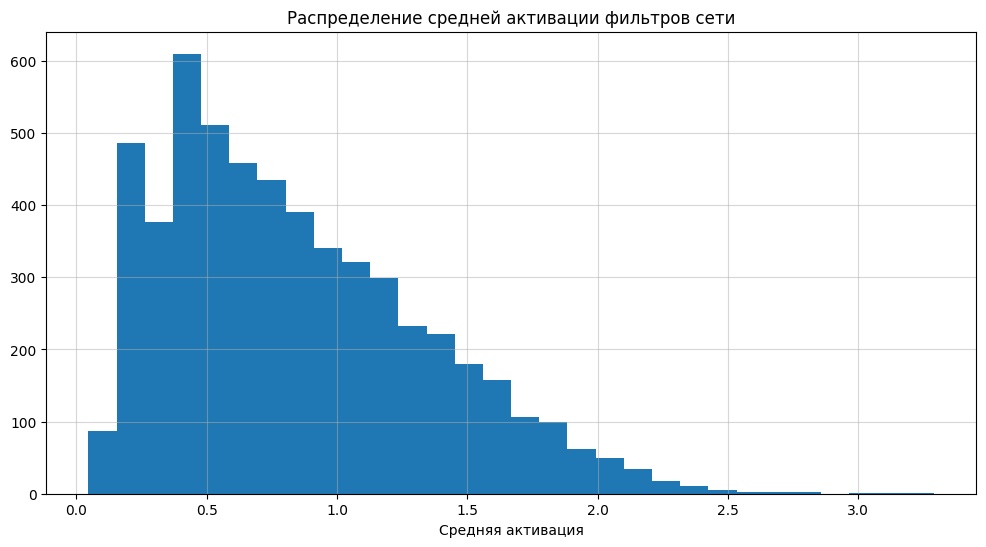

In [21]:
all_activations = torch.cat(list(mean_activation.values()))

plt.figure(figsize=(12, 6))

plt.hist(all_activations, bins=30)

plt.grid(True, alpha=0.5)

plt.xlabel('Средняя активация')

plt.title('Распределение средней активации фильтров сети')
plt.show()

График показывает, что распределение средней активации не является равномерным. Ее разброс от величин очень близких к нулю до значения более $2.5$. При этом наибольшее число фильтров имеют среднюю активацию около $0.5$. Посмотрим на распределение в зависимости от того, в какой группе находится сверточный слой (под группами подразумеваются conv1, conv2, ..., conv5).

In [22]:
conv_groups = [[] for i in range(5)]

cur_group = 0

for i in range(len(feature_extractor)):
    if str(feature_extractor[i])[:4] == 'Conv':
        conv_groups[cur_group].append(i)
    if str(feature_extractor[i])[:3] == 'Max':
        cur_group += 1

mean_activation_group = {i : torch.cat([mean_activation[j] for j in conv_groups[i]]) for i in range(5)}

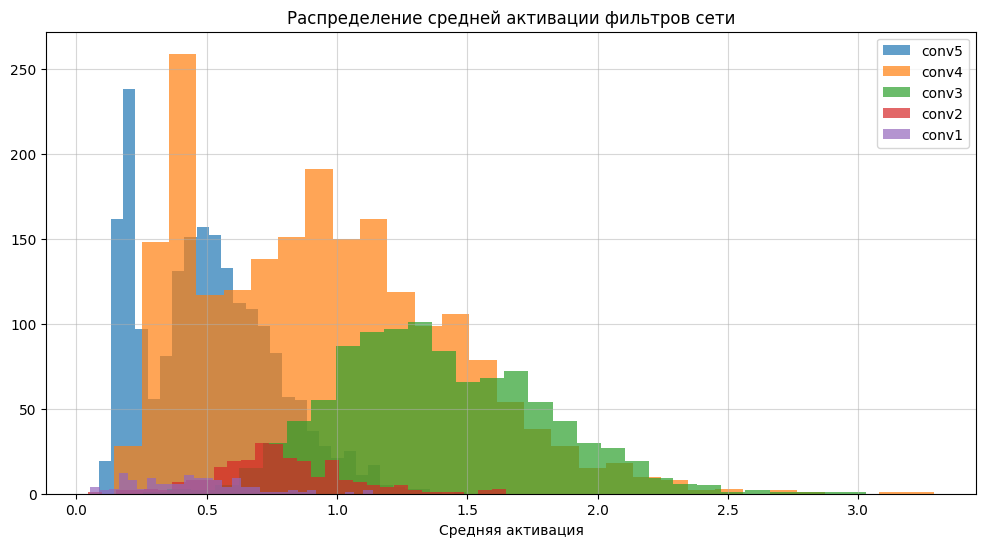

In [24]:
plt.figure(figsize=(12, 6))

for i in range(5)[::-1]:
    plt.hist(mean_activation_group[i], bins=30, alpha=0.7, label=f'conv{i + 1}')

plt.title('Распределение средней активации фильтров сети')
plt.xlabel('Средняя активация')

plt.grid(alpha=0.5)
plt.legend()

plt.show()

Здесь четко видно, что от слоя к слою распределение средней активации сильно варьируется. Например, можно сравнить средние активации фильтров из группы conv5 и группы conv3. Понятно, что из-за такой разницы вклад в лосс может быть действительно разным.

Приступим к нормализации. Стоит отметить, что мы нормализуем лишь часть feature extractor.

In [25]:
normalized_vgg = models.vgg19(pretrained=True)
res_feature_extractor = normalized_vgg.features

d:\Учеба\Анализ данных\hw5\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\Учеба\Анализ данных\hw5\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [26]:
# Сначала меняем первый сверточный слой
with torch.no_grad():

    res_feature_extractor[0].weight /= mean_activation[0][:, None, None, None]
    res_feature_extractor[0].bias /= mean_activation[0]

    prev_conv_id = 0

    # Далее, для каждого слоя в цикле
    for id in conv_id[1:]:
        res_feature_extractor[id].weight *= mean_activation[prev_conv_id][None, :, None, None]

        res_feature_extractor[id].weight /= mean_activation[id][:, None, None, None]
        res_feature_extractor[id].bias /= mean_activation[id]

        prev_conv_id = id

Посмотрим, какова теперь средняя активация на тестовой выборке.

In [27]:
after_mormalization = {conv_id[i] : torch.tensor([0.0] * feature_extractor[conv_id[i]].weight.shape[0]).to(device) \
                   for i in range(len(conv_id))}

for i in range(len(test)):
    compute_activation(normalized_vgg.features.to(device), test[i], after_mormalization)

    print(f'Вычислена активация для {i}')

for key in mean_activation:
    after_mormalization[key] /= len(test)
    after_mormalization[key] = after_mormalization[key].cpu()

Вычислена активация для 0
Вычислена активация для 1
Вычислена активация для 2
Вычислена активация для 3
Вычислена активация для 4
Вычислена активация для 5
Вычислена активация для 6
Вычислена активация для 7
Вычислена активация для 8
Вычислена активация для 9
Вычислена активация для 10
Вычислена активация для 11
Вычислена активация для 12
Вычислена активация для 13
Вычислена активация для 14
Вычислена активация для 15
Вычислена активация для 16
Вычислена активация для 17
Вычислена активация для 18
Вычислена активация для 19
Вычислена активация для 20
Вычислена активация для 21
Вычислена активация для 22
Вычислена активация для 23
Вычислена активация для 24
Вычислена активация для 25
Вычислена активация для 26
Вычислена активация для 27
Вычислена активация для 28
Вычислена активация для 29
Вычислена активация для 30
Вычислена активация для 31
Вычислена активация для 32
Вычислена активация для 33
Вычислена активация для 34
Вычислена активация для 35
Вычислена активация для 36
Вычислена а

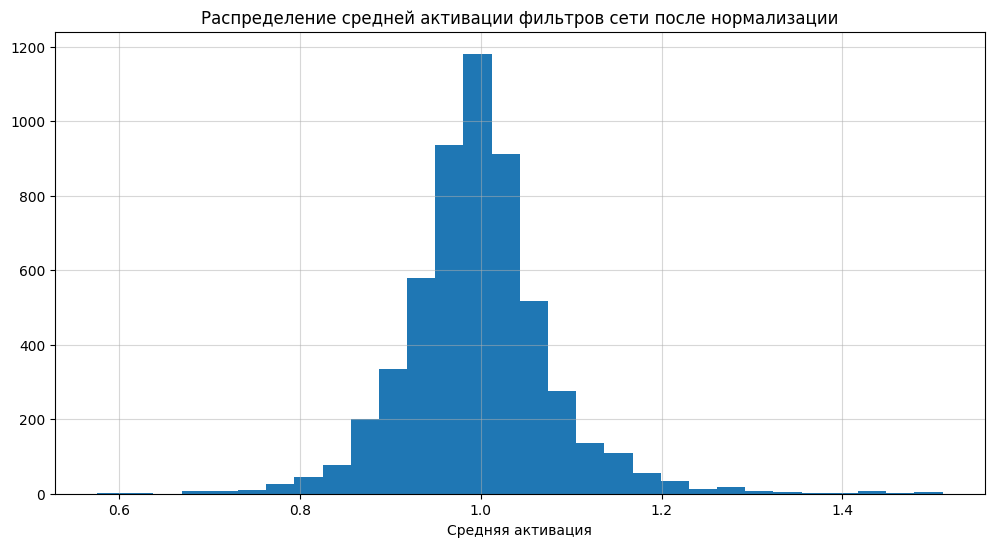

In [29]:
all_after_normalization = torch.cat(list(after_mormalization.values()))

plt.figure(figsize=(12, 6))

plt.hist(all_after_normalization, bins=30)

plt.grid(True, alpha=0.5)

plt.xlabel('Средняя активация')

plt.title('Распределение средней активации фильтров сети после нормализации')
plt.show()

Изображение напоминает плотность нормального распределения с мат. ожиданием, равным $1$. Таким образом, для большинства фильтров средняя активация находится в окретности единицы, чего мы и хотели.

Теперь сохраним модель и проверим, что она дает в задаче генерации текстуры.

In [30]:
torch.save(normalized_vgg, 'normalized_vgg.pt')